<div style="background:#152238;color:white;border-radius:14px;padding:28px 32px;">
 <div style="color:#9de2dc;letter-spacing:2px;font-size:12px;font-weight:bold;">AI ALGORITHMS · SEARCH LAB</div>

 <h1 align="center"><b>Lab sessions 1 &amp; 2:</b> Solving problems by searching<br><div style="color:#eebe5c;letter-spacing:2px;font-size:14px;font-weight:bold;">The Blind Catacombs: from blind exploration to guided search</div></h1>
 </div>

## <span style="color:#245b96;">Welcome to the Catacombs 🗝️: Find a Route from the Entrance to the Gate</span>


This practical work covers uninformed search (DFS, BFS, depth-limited search, iterative deepening, uniform-cost search), then informed search (heuristics, Greedy Best-First Search, A*). You will first model the problem, then implement and compare each strategy on a small graph and on several mazes. Finally, you will analyse the routes, costs, exploration effort and memory usage of the different methods.

Work through the notebook in order: implement each algorithm, test it, observe its behaviour and justify your conclusions with measurements and written answers.


This notebook is designed for two three-hour sessions, plus additional work outside class. The practical work must be completed in groups of three to four students.

<div style="border-left:5px solid #245b96;background:#eff5fc;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#245b96;">SETUP · Environment</strong><br>
The next cell installs any missing dependency in the active kernel (<code>pygame</code> for rendering, <code>imageio-ffmpeg</code> for MP4 encoding); it needs internet access. After updating the lab files, rerun the imports cell.
</div>

The pre-rendered clip below shows random navigation on the Lantern Room (uniform legal moves, revisits allowed, seed 7): once the exit is reached, the walk is shown without its detours and the hero follows that route. The later animations show the search traces produced by your own implementations, so that you can check their logic.

In [1]:
# Install only missing packages into THIS notebook's Python environment.
import importlib.util
import subprocess
import sys

required_packages = {
    "numpy": "numpy>=1.24,<3",
    "matplotlib": "matplotlib>=3.7,<4",
    "pandas": "pandas>=2.0,<4",
    "IPython": "ipython>=8,<10",
    "pygame": "pygame-ce>=2.5.8,<3",
    "imageio_ffmpeg": "imageio-ffmpeg>=0.6,<1",
}
missing_packages = [package for module, package in required_packages.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    print("Installing missing lab dependencies:", ", ".join(missing_packages))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])
    importlib.invalidate_caches()
print("Lab dependencies ready. Notebook Python:", sys.executable)

Lab dependencies ready. Notebook Python: /home/lain/cours/AI_algo/.venv/bin/python


In [2]:
import math
import numpy as np
import pandas as pd
from IPython.display import Video, display
# Refresh the lab helpers after a file update in a running kernel (dependency order).
# Restarting the kernel is equivalent; objects created before the reload should be rebuilt.
import importlib
import sys

importlib.invalidate_caches()
for _module_name in ("engine.core.grid", "engine.core.problem", "engine.render.theme", "engine.render.tiles",
                     "engine.render.animation", "engine.render.renderer", "catacombs_lab.models",
                     "catacombs_lab.costs", "catacombs_lab.examples", "catacombs_lab.core",
                     "catacombs_lab.cinema", "catacombs_lab.visuals", "catacombs_lab"):
    if _module_name in sys.modules:
        importlib.reload(sys.modules[_module_name])

from catacombs_lab import (
    Node, Stack, Queue, PriorityQueue, record_step,
    DungeonMap, DungeonPathProblem, GraphProblem, Problem, CUTOFF,
    load_map, available_mazes, run_search, check_solution, check_run, check_comparison, check_heuristic,
    benchmark, summarize, unit_cost, random_costs, with_costs,
    animate_run, save_movie, show_node_path, show_graph,
    example_graph, trace_graph, EXAMPLE_EXPECTED,
)

EXPANSION_BUDGET = 50000
TIMING_REPEATS = 7

def report(*runs):
    """Print just the result measures used in the exercise."""
    for r in runs:
        if r.status == "solved":
            print(f"{r.dungeon.name} | {r.name}: {r.length} moves, cost {r.cost:g}, "
                  f"{r.expansions} expansions, peak {r.memory_label.lower()} {r.peak_frontier}.")
        else:
            print(f"{r.dungeon.name} | {r.name}: {r.status}; {r.expansions} expansions; no returned route.")

In [3]:
# Random navigation on the Lantern Room: uniform legal moves, seed 7; the route without detours is then followed (pre-rendered).
display(Video("catacombs_lab/assets/maze_search_example.mp4", embed=True, width=1100,
              html_attributes='controls loop playsinline style="max-width:100%;height:auto;border-radius:12px"'))

### Roadmap

1. **Formulate the problem** — `Problem`, `Node`, an example graph. *Q1*
2. **Uninformed search** — the supplied DFS (*D1*), then BFS (*I1*). *Q2*
3. **Search with a depth limit** — DLS and IDS (*I2*). *Q3*
4. **Uniform-cost search** (*I3*) and the comparison of the uninformed methods. *Q4, Q5*
5. **Heuristics** (*I4*).
6. **Greedy Best-First Search** (*I5*). *Q6*
7. **A\*** (*I6*) and state reopening. *Q7, Q8*
8. **Experiments** *E1–E3*. *Q9, Q10*
9. **Synthesis.** *Q11, Q12*
10. **Optional extension** for bonus points.
11. **Submission** and example questions to prepare your oral assessment.

Each algorithm follows the same rhythm: implement it, check it on an example graph, run it on a maze, observe, explain. Orange IMPLEMENT boxes ask for code; purple EXPLAIN, DISCUSS and SYNTHESISE boxes ask for written answers only.

<div style="border-left:5px solid #245b96;background:#eff5fc;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#245b96;">PACING · Two sessions of 3 hours + personal work</strong><br>
<strong>Lab Session 1</strong>: Sections 1–4 (I1–I3, Q1–Q5). <br><strong>Lab Session 2</strong>: Sections 5–9 (I4–I6, E1–E3, Q6–Q12).<br>
<strong>Personal work</strong>: complete the written answers with your own measurements, write the synthesis (Q12), optionally Section 10. Section 11 gives examples of questions asked during the oral assessment, which will take place during the Lab 4 session.
</div>

## 1 · Formulate the problem

The task is to navigate from the maze entrance **S** to the exit **E** without crossing walls. A solution is a sequence of legal moves; depending on the objective we may seek any valid route, the fewest moves, or the lowest travel cost. We first write the problem formulation and its Python representation, then implement the search algorithms on this common model.

### 1.1 The six elements of a search problem

| Element | Formulation for the maze | Python |
|:---|:---|:---|
| **State space** | All traversable positions `(x, y)` of the grid; walls are excluded. | reachable through `actions` and `result` |
| **Initial state** | The position of the entrance **S**. | `problem.initial` |
| **Goal test** IS-GOAL(s) | The current position is the exit **E**. | `problem.goal_test(state)` |
| **Actions** ACTIONS(s) | Moves **N, E, S, W** that lead to a traversable neighbouring cell. | `problem.actions(state)` |
| **Transition model** RESULT(s, a) | The position reached after applying a legal action. | `problem.result(state, action)` |
| **Action cost** ACTION-COST(s, a, s') | The entry cost of the cell reached by the move. | `problem.action_cost(state, action, next_state)` |

A state records only the current position; the maze and the exit remain fixed during a search. Coordinates increase to the right (`x`) and downwards (`y`). The initial cost is zero; with unit costs, the total cost equals the number of moves. Weighted terrain (stone 1, gravel 2, mire 5) distinguishes the fewest moves from the lowest cost.

### 1.2 The `Problem` class

The `Problem` class is the common interface used throughout this lab: `initial` and `goal` store the endpoints, the methods define actions, transitions, goal test and costs. Search algorithms only use this interface. It is supplied in `catacombs_lab/models.py`:

```python
class Problem:
    def __init__(self, initial, goal=None):
        self.initial = initial
        self.goal = goal

    def actions(self, state):                       # ACTIONS(s)
        raise NotImplementedError

    def result(self, state, action):                # RESULT(s, a)
        raise NotImplementedError

    def goal_test(self, state):                     # IS-GOAL(s)
        if isinstance(self.goal, list):
            return state in self.goal
        return state == self.goal

    def action_cost(self, state, action, next_state):   # ACTION-COST(s, a, s')
        return 1

    def path_cost(self, c, state1, action, state2):     # cumulative form: the NEW total cost
        return c + self.action_cost(state1, action, state2)
```

To model a domain, subclass `Problem` and define `actions` and `result`; override `action_cost` for non-unit step costs, or `goal_test` for another goal condition. `path_cost` returns the cumulative cost `c + ACTION-COST`, which is what a node stores.

### 1.3 Specialise `Problem` for the maze

`DungeonMap` stores the grid, entrance, exit and terrain; `DungeonPathProblem` (supplied, already imported) implements the interface on it:

```python
class DungeonPathProblem(Problem):
    DIRECTIONS = {"N": (0, -1), "E": (1, 0), "S": (0, 1), "W": (-1, 0)}

    def __init__(self, dungeon: DungeonMap):
        super().__init__(initial=dungeon.start, goal=dungeon.goal)
        self.dungeon = dungeon

    def actions(self, state):
        x, y = state
        return [action for action, (dx, dy) in self.DIRECTIONS.items()
                if self.dungeon.passable(x + dx, y + dy)]

    def result(self, state, action):
        dx, dy = self.DIRECTIONS[action]
        return state[0] + dx, state[1] + dy

    def action_cost(self, state, action, next_state):
        return self.dungeon.terrain_cost(*next_state)
```

`action_cost` is the cost of **one** move (the entry cost of the destination); `path_cost` returns the updated cumulative cost: entering a cell of cost 5 after accumulating 7 returns 12.

### 1.4 Represent a candidate route with `Node`

A node associates a state with one route reaching it. Two routes can reach the same state with different parents, depths and costs: a state occurs once in the state space, but each node is an entire path.

```python
Node(state, parent=None, action=None, path_cost=0)
```

| Node member | Meaning |
|:---|:---|
| `state`, `parent`, `action` | The current state and how this route reached it |
| `path_cost` | The cumulative cost **g** from the root, initially 0 |
| `depth` | Number of actions from the root |
| `child_node(problem, action)` | Build a child with its parent, cost and depth (CHILD-NODE) |
| `expand(problem)` | Generate one level of children in the problem's action order (EXPAND) |
| `path()` | All nodes from the root to this node, **including the root** |
| `solution()` | Only the route's actions; `[]` at the root |

```python
def child_node(self, problem, action):
    state2 = problem.result(self.state, action)
    return Node(state2, self, action,
                problem.path_cost(self.path_cost, self.state, action, state2))
```

Node equality and hashing use the state. Search functions return `node.solution()`: `[]` is a valid route when the initial state is already the goal, `None` denotes exhaustive failure. The models, child generation and containers (`Stack`, `Queue`, `PriorityQueue`) are supplied; you implement frontier selection, duplicate handling and stopping rules.

Initial: (1, 1) Goal: (7, 1) Legal actions: ['E', 'S']
After two moves: state, depth, path_cost = (3, 1) 2 2
Node.path(): [(1, 1), (2, 1), (3, 1)]
Node.solution(): ['E', 'E']
Model checks passed: root, parent chain, depth, action cost and cumulative cost.


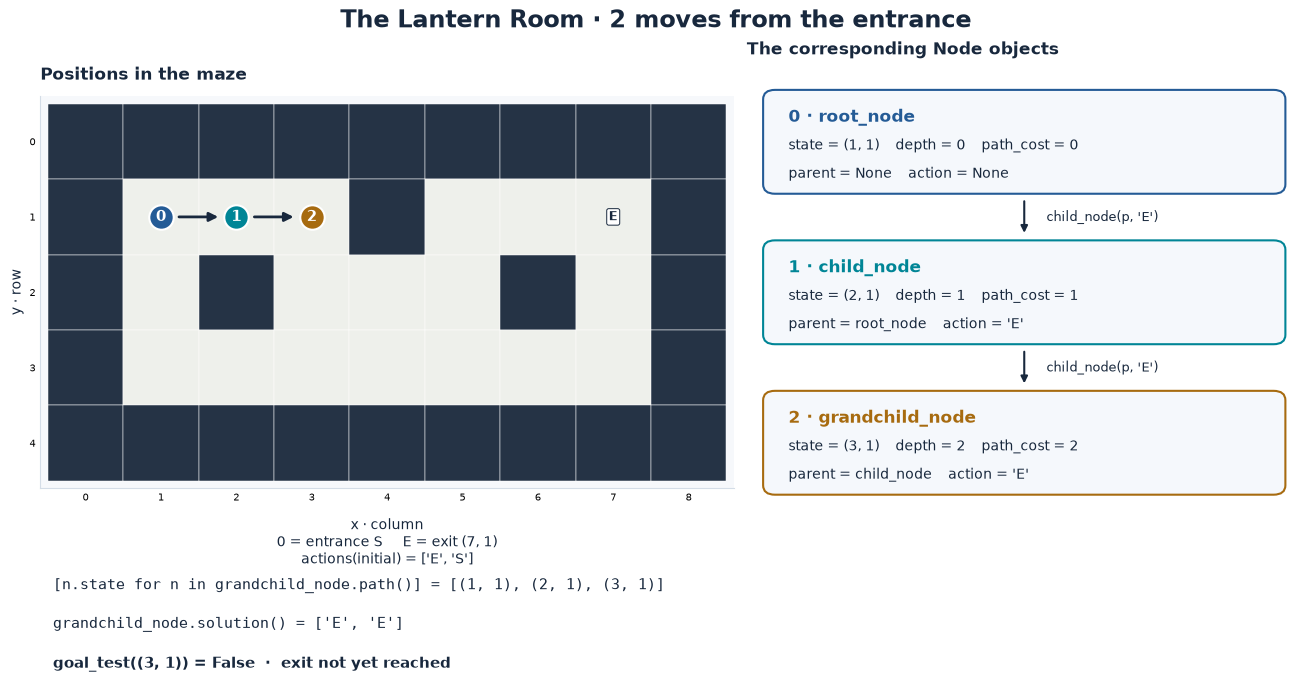

In [4]:
tiny = DungeonMap("""@name: The Lantern Room
#########
#S..#..E#
#.#...#.#
#.......#
#########
""")
p = DungeonPathProblem(tiny)
root_node = Node(p.initial)
child_node = root_node.child_node(p, "E")
grandchild_node = child_node.child_node(p, "E")

print("Initial:", p.initial, "Goal:", p.goal, "Legal actions:", p.actions(p.initial))
print("After two moves: state, depth, path_cost =",
      grandchild_node.state, grandchild_node.depth, grandchild_node.path_cost)
print("Node.path():", [node.state for node in grandchild_node.path()])
print("Node.solution():", grandchild_node.solution())

assert isinstance(p, Problem)
assert p.goal_test(p.goal) and not p.goal_test(p.initial)
assert root_node.path() == [root_node] and root_node.solution() == []
assert child_node.parent is root_node and child_node.depth == 1
assert grandchild_node.depth == 2 and grandchild_node.path_cost == 2
assert grandchild_node.solution() == ["E", "E"]  # sequence of actions from root to grandchild
assert p.action_cost(root_node.state, "E", child_node.state) == 1        # ACTION-COST of one move
assert p.path_cost(7, root_node.state, "E", child_node.state) == 8       # cumulative cost
print("Model checks passed: root, parent chain, depth, action cost and cumulative cost.")

# Relate the three nodes to their positions and transitions in the maze.
display(show_node_path(p, grandchild_node,
                       labels=["root_node", "child_node", "grandchild_node"]))

### 1.5 An example graph with known traces

The same interface represents a small directed graph (start **S**, goal **G**) on which the trace of every algorithm is known. `GraphProblem` stores a road map as `state -> {neighbour: step cost}`; an action is the name of the neighbour it leads to. It records the order in which states are goal-tested (`tested`) and expanded (`expanded`), so that `trace_graph` can compare your implementation with the expected trace before you run it on a maze. The next cell draws the graph with the cost of each edge.

States: ['S', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
Initial: S | Goal: G
ACTIONS(S) = ['A', 'B', 'C'] | RESULT(S, 'A') = A | ACTION-COST(S, 'A', A) = 5
Edges: {'S': {'A': 5, 'B': 2, 'C': 4}, 'A': {'D': 9, 'E': 4}, 'B': {'G': 6}, 'C': {'F': 2}, 'D': {'H': 7}, 'E': {'G': 6}, 'F': {'G': 1}}


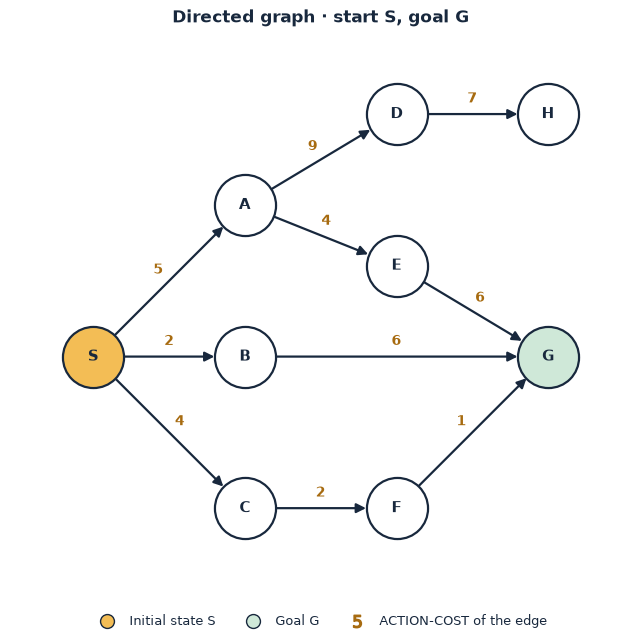

In [5]:
example = example_graph()        # S->A 5, S->B 2, S->C 4, A->D 9, A->E 4, B->G 6, C->F 2, D->H 7, E->G 6, F->G 1
print("States:", example.states())
print("Initial:", example.initial, "| Goal:", example.goal)
print("ACTIONS(S) =", example.actions("S"), "| RESULT(S, 'A') =", example.result("S", "A"),
      "| ACTION-COST(S, 'A', A) =", example.action_cost("S", "A", "A"))
print("Edges:", {state: neighbours for state, neighbours in example.edges.items() if neighbours})
display(show_graph(example))       # states as circles, ACTION-COST on each edge
_ = example.reset()              # forget the requests made by the prints above

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q1 · Formulate the two problems</strong><br>
Written answer only, no code to write: the classes above are supplied and already imported. Give the six elements (state space, initial state, goal test, actions, transition model, action cost) for the maze and for the example graph. What is a state, a node, a path, a solution and an optimal solution here? Give one example of two different nodes with the same state.
</div>

**Your answer:** …

## 2 · Uninformed search

Uninformed search, also known as blind search, uses no information about where the exit lies: it can only explore the maze systematically from the entrance, one state after another, while remembering what it has already seen. The strategies of Sections 2 to 4 differ in the order in which they explore, and that order decides the route they return and the effort they spend. We begin with depth-first search, which is supplied.

### 2.1 Depth-first search — a complete worked example

**Observe after running:** how does DFS follow one branch before exploring another?

The frontier is a `Stack`. The start is marked as reached immediately, then the loop pops a node, tests the goal and pushes its unreached children. One set, `reached`, holds the states already in the frontier or already explored; it is updated **when pushing**, which prevents several pending copies of a state. Children are pushed in `reversed(node.expand(problem))`, so that the first legal action (N before E, S, W) is popped first. On our finite maps this graph DFS terminates and is complete; it does not optimise moves or cost.

**DFS is provided.** Read its numbered blocks, run the cell, and relate the exploration order to the stack.

<div style="border-left:5px solid #245b96;background:#eff5fc;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#245b96;">WORKED EXAMPLE · D1 · Read and Run DFS</strong><br>
Read and run the code, follow the animation, and interpret the results. You are not required to rewrite DFS.
</div>

In [6]:
def depth_first_search(problem, log=None):
    """D1 — supplied graph DFS: LIFO frontier and a reached set."""
    # 1. A node stores one path; the stack stores the paths still waiting to be tried.
    root = Node(problem.initial)
    frontier = Stack()                         # LIFO: the newest entry leaves first.
    frontier.push(root)
    reached = {root.state}                     # explored states ∪ frontier states, marked on insertion.
    record_step(log, root, frontier, note="Initialize LIFO frontier")

    while frontier:
        # 2. Choose the next path with the frontier discipline (the deepest node).
        node = frontier.pop()
        record_step(log, node, frontier, event="select", note="Select the last inserted node")

        # 3. Goal test when the node is selected.
        if problem.goal_test(node.state):
            record_step(log, node, frontier, event="goal", note="Goal selected; reconstruct its parent chain")
            return node.solution()          # [] is a valid plan when start == goal.

        # 4. EXPAND in reverse order so that the first legal action is popped first.
        for child in reversed(node.expand(problem)):
            if child.state in reached:        # already in the frontier or explored
                continue
            # 5. child_node has set parent, action, depth and path_cost (= g).
            reached.add(child.state)
            frontier.push(child)

        # 6. This line only observes the frontier; it never makes a search decision.
        record_step(log, node, frontier, event="expand", note="Push unreached children in reverse action order")

    # 7. An empty frontier means the reachable finite component was exhausted.
    return None

### Read the example before changing it

| Code block | Mechanism | Check your understanding |
|:---|:---|:---|
| **1** | Initialise a stack and mark S as reached | Why include S in the set immediately? |
| **2–3** | Pop a node, then test the goal | Why can the return value legitimately be `[]`? What changes if the goal is tested when a child is generated instead? |
| **4** | Reverse the insertion order | With legal actions `[N, E, S]`, in what order are they pushed and popped? |
| **5** | Use `child_node` and mark `reached` on push | Can two pending entries hold the same state in this DFS? |
| **6** | Record what happened | Would removing `record_step` change the returned plan? |
| **7** | Return `None` on exhaustion | Which finite search space has just been exhausted? |

**D1 · Your reading notes:** explain how blocks 4 and 5 determine the exploration order and prevent duplicate pending states.

**Your reading notes:** …

In [7]:
# Why does block 4 of the DFS push the children in REVERSED order?
# A stack pops the last pushed item first: reversing makes the first legal action leave first.
legal_actions = ["N", "E", "S"]            # the order returned by problem.actions(state)

demo_stack = Stack()
for action in reversed(legal_actions):     # pushes S, then E, then N
    demo_stack.push(action)
print("Legal actions:            ", legal_actions)
print("Pushed in reversed order: ", list(reversed(legal_actions)))
print("Popped (last in, first out):", [demo_stack.pop() for _ in range(3)], "-> N is tried first, as listed")

without_reversal = Stack()
for action in legal_actions:               # pushes N, then E, then S
    without_reversal.push(action)
print("Without reversing, popped:  ", [without_reversal.pop() for _ in range(3)], "-> the last action would be tried first")

Legal actions:             ['N', 'E', 'S']
Pushed in reversed order:  ['S', 'E', 'N']
Popped (last in, first out): ['N', 'E', 'S'] -> N is tried first, as listed
Without reversing, popped:   ['S', 'E', 'N'] -> the last action would be tried first


### Run and inspect DFS

<div style="border-left:5px solid #245b96;background:#eff5fc;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#245b96;">Recording and execution</strong><br><code>record_step</code> records selections and expansions. <code>run_search</code> executes the function, checks the returned actions and measures the search effort with two counters shown in every table: <strong>expansions</strong>, the number of calls to <code>actions</code> (the work done), and <strong>peak</strong>, the largest number of entries held in the frontier at any moment during the search (the memory used; the <code>reached</code> set is not counted).
</div>

`MAZE_NAME` selects the maze: a name from `available_mazes()`, or an existing `DungeonMap` such as `tiny`. `check_run` validates the returned route, `report` summarises the result, `animate_run` displays the recorded exploration. A `budget` status means the expansion allowance interrupted the search; it does not establish that the exit is unreachable.

In [8]:
MAZE_NAME = "flooded_gallery"  # Any name from available_mazes(), or a DungeonMap.
dfs_run = run_search(maze=MAZE_NAME, solver=depth_first_search, name="DFS")
check_run(dfs_run)
display(animate_run(dfs_run))
report(dfs_run)

The Flooded Gallery | DFS: 44 moves, cost 44, 72 expansions, peak frontier entries 20.


### 2.2 Breadth-first search (BFS)

BFS expands the shallowest node first: the frontier is a FIFO queue, so routes are generated in order of their number of moves. The supplied `Queue` provides `push`, `pop` (oldest first) and `len`.

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I1 · Breadth-first search</strong><br>Complete <code>breadth_first_search</code> from the DFS skeleton: replace the stack by the queue, insert the children in their natural action order, keep the <code>reached</code> set and the goal test on selection. Then run the check on the example graph and the comparison with DFS.
</div>

In [9]:
def breadth_first_search(problem, log=None):
    """I1: implement breadth-first search.

    Return node.solution() for the first goal selected from the FIFO frontier,
    [] if the initial state is a goal, None if the frontier empties.
    """
    root = Node(problem.initial)
    frontier = Queue()                         # FIFO: the oldest entry leaves first.
    frontier.push(root)
    reached = {root.state}                     # explored states ∪ frontier states, marked on insertion.
    record_step(log, root, frontier, note="Initialize FIFO frontier")

    while frontier:
        # 2. Choose the next path with the frontier discipline (the deepest node).
        node = frontier.pop()
        record_step(log, node, frontier, event="select", note="Select the last inserted node")

        # 3. Goal test when the node is selected.
        if problem.goal_test(node.state):
            record_step(log, node, frontier, event="goal", note="Goal selected; reconstruct its parent chain")
            return node.solution()          # [] is a valid plan when start == goal.
        
        for child in node.expand(problem):
            if child.state in reached:        # already in the frontier or explored
                continue
            # 5. child_node has set parent, action, depth and path_cost (= g).
            reached.add(child.state)
            frontier.push(child)

        record_step(log, node, frontier, event="expand", note="Push unreached children in action order")

    return None

In [10]:
# Check on the example graph: expected traces of DFS and BFS.
for name, solver in (("DFS", depth_first_search), ("BFS", breadth_first_search)):
    trace = trace_graph(solver, example_graph())
    expected = EXAMPLE_EXPECTED[name]
    print(f"{name}: tested {trace['tested']} | plan {trace['plan']} | cost {trace['cost']}")
    assert trace["tested"] == expected["tested"], f"{name}: the order of goal tests differs from the expected trace"
    assert trace["plan"] == expected["path"] and trace["cost"] == expected["cost"], f"{name}: route or cost differs from the expected trace"
print("DFS and BFS reproduce the expected traces.")

DFS: tested ['S', 'A', 'D', 'H', 'E', 'G'] | plan ['A', 'E', 'G'] | cost 15
BFS: tested ['S', 'A', 'B', 'C', 'D', 'E', 'G'] | plan ['B', 'G'] | cost 8
DFS and BFS reproduce the expected traces.


In [11]:
MAZE_NAME = "flooded_gallery"
bfs_run = run_search(maze=MAZE_NAME, solver=breadth_first_search, name="BFS")
dfs_reference = run_search(maze=MAZE_NAME, solver=depth_first_search, name="DFS")
if check_comparison(bfs_run, dfs_reference):
    assert bfs_run.length <= dfs_reference.length, "BFS should minimise moves."
display(animate_run(bfs_run))
report(dfs_reference, bfs_run)

The Flooded Gallery | DFS: 44 moves, cost 44, 72 expansions, peak frontier entries 20.
The Flooded Gallery | BFS: 32 moves, cost 32, 117 expansions, peak frontier entries 8.


<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q2 · Compare DFS and BFS</strong><br>On the example graph, why does DFS test S, A, D, H, E, G while BFS tests S, A, B, C, D, E, G, and why do their routes differ (cost 15 versus 8)? On the maze, compare exploration order, moves, expansions and peak frontier. Distinguish what you observe from what the algorithms guarantee.
</div>

**Your answer:** …

## 3 · Search with a depth limit

DFS follows one branch as far as it can before backtracking. On a large or cyclic space, that branch can become very long. A **depth limit** bounds the number of moves a branch may make from the entrance.

### 3.1 Depth-limited search (DLS)

`depth_limited_search(problem, limit)` is DFS with a maximum depth `limit`, counted in moves from the entrance. Three things change with respect to the supplied DFS:

- **Depth limit.** A node at depth `limit` is not expanded: it is treated as if it had no successors. The goal is still tested when the node is popped, so a goal at depth `limit` is found.
- **No global explored set.** A child is skipped only if its state already appears on the path of its own node (a cycle). The same state may therefore be reached again through a different, possibly shorter, path.
- **Three possible return values**, summarised below.

| Return value | Meaning | Example |
|:---|:---|:---|
| a list of actions | a route to the exit exists within `limit` moves | Recursion Room, `limit=4`: the 4-move route |
| `CUTOFF` (supplied constant) | no route within `limit` moves, but at least one branch was stopped by the limit: a longer route may exist, the search is **inconclusive** | Recursion Room, `limit=3`: the 4-move route is out of reach |
| `None` | no route at all: every branch ended because of a cycle, never because of the limit, so the exit is unreachable (**exhaustive failure**) | Sealed Cell, `limit=3`: the entrance corridor is fully explored |

`None` proves that no route exists; `CUTOFF` proves nothing.

### 3.2 Iterative deepening (IDS)

`iterative_deepening_search(problem)` calls DLS with `limit` = 0, then 1, then 2, and so on; each pass starts again from the entrance. It stops at the first pass whose result is not `CUTOFF`: either a route, which then has the fewest possible moves since no smaller limit found one, or `None`, when the exit is unreachable. The repeated passes cost time, but the memory stays that of a single DLS pass.

Three different limits appear in this section; keep them apart:

| Limit | Where | Effect |
|:---|:---|:---|
| `limit` | argument of `depth_limited_search` | maximum number of moves in one DLS pass |
| `max_depth` | optional argument of `iterative_deepening_search` | last limit that IDS tries; if that pass still returns `CUTOFF`, IDS returns `CUTOFF` |
| `budget` | argument of `run_search` | maximum total number of expansions of a run; beyond it, the run is reported with status `budget` and no route |

`run_search` reports each outcome as a status: `solved` (a route), `cutoff`, `failure` (`None`) or `budget`.

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I2 · DLS and IDS</strong><br>Complete <code>depth_limited_search</code> from the DFS skeleton, applying the three rules of 3.1 (depth limit, cycle check with <code>node.path()</code> instead of <code>reached</code>, three return values), then write <code>iterative_deepening_search</code> as described in 3.2. For the animation, record the events <code>"limit"</code>, <code>"cutoff"</code> and <code>"pass_end"</code> as documented in <code>help(record_step)</code>.
</div>

In [ ]:
def depth_limited_search(problem, limit, log=None):
    """I2: implement depth-limited search.

    Return node.solution() for a goal selected within the limit, CUTOFF when a
    branch reached depth `limit` without a solution, None on exhaustive failure.
    """
    # 1. A node stores one path; the stack stores the paths still waiting to be tried.
    root = Node(problem.initial)
    frontier = Stack()                         # LIFO: the newest entry leaves first.
    frontier.push(root)
    
    record_step(log, root, frontier, note="Initialize LIFO frontier")

    while frontier:
        # 2. Choose the next path with the frontier discipline (the deepest node).
        node = frontier.pop()
        record_step(log, node, frontier, event="select", note="Select the last inserted node")

        # 3. Goal test when the node is selected.
        if problem.goal_test(node.state):
            record_step(log, node, frontier, event="goal", note="Goal selected; reconstruct its parent chain")
            return node.solution()          # [] is a valid plan when start == goal.

        # 4. EXPAND in reverse order so that the first legal action is popped first.
        for child in reversed(node.expand(problem)):
            if child.state in node.path():        # already in the frontier or explored
                continue
            # 5. child_node has set parent, action, depth and path_cost (= g).
            node.path().add(child.state)
            frontier.push(child)

        # 6. This line only observes the frontier; it never makes a search decision.
        record_step(log, node, frontier, event="expand", note="Push unreached children in reverse action order")

    # 7. An empty frontier means the reachable finite component was exhausted.
    return None

In [ ]:
def iterative_deepening_search(problem, log=None, max_depth=None):
    """I2: implement iterative deepening search.

    Call depth_limited_search with limit 0, 1, 2, … (up to max_depth if given)
    and return its result as soon as it is not CUTOFF.
    """
    raise NotImplementedError("I2: implement IDS")

### 3.3 Inspect the recorded traversal

Both cells use `recursion_room` and display every recorded event: follow the cutoffs and, for IDS, the successive depth limits (each pass restarts from the entrance; total work accumulates).

In [ ]:
MAZE_NAME = "recursion_room"
dls_demo = run_search(maze=MAZE_NAME, solver=depth_limited_search,
                      limit=3, trace_limit=2000, name="DLS / detailed")
print(check_run(dls_demo))
display(animate_run(dls_demo, explore_frames=None, step_seconds=0.65))

In [ ]:
MAZE_NAME = "recursion_room"
ids_demo = run_search(maze=MAZE_NAME, solver=iterative_deepening_search,
                      max_depth=4, trace_limit=2000, name="IDS / detailed")
print(check_run(ids_demo))
display(animate_run(ids_demo, explore_frames=None, step_seconds=0.65))

### 3.4 Compare depth limits and search effort

Run DLS on the Lantern Room with the proposed limits, then compare its last run with IDS and BFS. The last lines run IDS on the Flooded Gallery, whose cells can be reached by many different paths: compare its expansions with those of BFS.

In [ ]:
MAZE_NAME = tiny
DEPTH_LIMITS = (0, 2, 4, 6, 8)

dls_runs = [
    run_search(maze=MAZE_NAME, solver=depth_limited_search, limit=limit,
               record=False, name=f"DLS / L={limit}")
    for limit in DEPTH_LIMITS
]
dls_results = pd.DataFrame([
    dict(limit=limit, **run.summary()) for limit, run in zip(DEPTH_LIMITS, dls_runs)
])
print("DLS: vary the depth limit")
display(dls_results[["limit", "status", "length", "expansions", "peak_frontier"]]
        .rename(columns={"length": "moves", "peak_frontier": "peak"}))

bfs_depth_reference = run_search(maze=MAZE_NAME, solver=breadth_first_search,
                                 record=False, name="BFS")
ids_run = run_search(maze=MAZE_NAME, solver=iterative_deepening_search,
                     name="IDS", trace_limit=2000)
check_comparison(*dls_runs, ids_run, bfs_depth_reference)
if ids_run.status == "solved" and bfs_depth_reference.status == "solved":
    assert ids_run.length == bfs_depth_reference.length, "IDS should minimise moves like BFS."
depth_comparison = pd.DataFrame([
    run.summary() for run in (dls_runs[-1], ids_run, bfs_depth_reference)
])
print("Compare the last DLS run with IDS and BFS")
display(depth_comparison[["method", "status", "length", "expansions", "unique_expanded", "peak_frontier"]]
        .rename(columns={"length": "moves", "unique_expanded": "distinct_states", "peak_frontier": "peak"}))
display(animate_run(ids_run, explore_frames=None))

# A grid with many alternative paths to the same cell: IDS repeats far more work than BFS.
gallery_bfs = run_search(maze="flooded_gallery", solver=breadth_first_search, record=False, name="BFS")
gallery_ids = run_search(maze="flooded_gallery", solver=iterative_deepening_search,
                         record=False, budget=2_000_000, name="IDS")
check_comparison(gallery_bfs, gallery_ids)
report(gallery_bfs, gallery_ids)

### 3.5 Check the return values and the handling of repeated states

The first cell distinguishes a depth cutoff, an exhausted search and a budget stop. The second uses the Twin Doors, an open hall where every cell can be reached by many paths of different lengths: IDS must still return a route with the fewest moves. The last cell checks the IDS passes on the example graph.

In [ ]:
# Fixed checks, independent of the maze selected for the experiment.
sealed_fixture = DungeonPathProblem(load_map("sealed_cell"))
assert depth_limited_search(sealed_fixture, 0) == CUTOFF
assert depth_limited_search(sealed_fixture, 3) is None
assert iterative_deepening_search(sealed_fixture) is None

budget_check = run_search(maze="recursion_room", solver=iterative_deepening_search,
                          budget=1, record=False, name="IDS / budget check")
assert budget_check.status == "budget" and budget_check.plan is None
check_run(budget_check)
print("Depth-search interface checks passed.")

In [ ]:
MAZE_NAME = "twin_doors"   # an open hall: many different paths lead to the same cell
twin_bfs = run_search(maze=MAZE_NAME, solver=breadth_first_search, record=False, name="BFS")
twin_ids = run_search(maze=MAZE_NAME, solver=iterative_deepening_search, record=False,
                      budget=2_000_000, name="IDS")
if check_comparison(twin_bfs, twin_ids):
    assert twin_ids.length == twin_bfs.length, (
        "IDS must return a shortest route: reject a repeated state only when it lies on the current path")
report(twin_bfs, twin_ids)

In [ ]:
# Check on the example graph: expected IDS passes (limit 0 tests S only, then limits 1 and 2).
trace = trace_graph(iterative_deepening_search, example_graph())
expected = EXAMPLE_EXPECTED["IDS"]
print("IDS tested order:", trace["tested"], "| plan", trace["plan"], "| cost", trace["cost"])
assert trace["tested"] == ["S"] + expected["tested_limit1"] + expected["tested_limit2"], "the passes differ from the expected trace"
assert trace["plan"] == expected["path"] and trace["cost"] == expected["cost"]
print("IDS reproduces the expected passes.")

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">DISCUSS · Q3 · Depth limits, repeated work and repeated states</strong><br>How do you distinguish a solution, a cutoff, an exhaustive failure and a budget stop? How does the limit affect DLS, and what trade-off does IDS make? Why does DLS reject a repeated state only along the current path rather than with a global explored set? Why does IDS need so many more expansions than BFS on the Flooded Gallery, although the repeated work of IDS is usually considered cheap? Use the route lengths, expansion counts and peaks, with BFS as reference.
</div>

**Your answer:** …

## 4 · Uniform-cost search (UCS)

When step costs vary, BFS finds the fewest steps but not necessarily the cheapest route. UCS expands the node with the lowest path cost g: the frontier is a `PriorityQueue` keyed by `node.path_cost`, and a `reached` table maps each state to the best node found so far. A child is inserted only if its state is new or its g is strictly lower, in which case it replaces the table entry.

The supplied queue provides `push(node, priority)` and `pop()` (lowest priority first, FIFO on ties) but no membership test or deletion: an older, dearer entry for the same state stays in the queue and is discarded when it is popped, because it no longer matches the node stored in `reached`. The goal is tested when a node is **dequeued**, never when it is generated.

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I3 · Uniform-cost search</strong><br>Complete <code>uniform_cost_search</code>: priority queue keyed by <code>node.path_cost</code>, <code>reached</code> dictionary from state to best node, insertion only when the child's g is strictly lower, skip of stale entries after <code>pop()</code>, goal test on the dequeued node. Then run the check on the example graph and compare it with BFS under the cost models below.
</div>

In [ ]:
def uniform_cost_search(problem, log=None):
    """I3: implement uniform-cost search.

    Frontier: PriorityQueue keyed by node.path_cost. reached: dict state -> best node.
    Return node.solution() for the first goal dequeued, [] at the root, None on failure.
    """
    raise NotImplementedError("I3: implement UCS")

### 4.1 Choose a cost model

Each map has its own terrain: entering stone costs 1, gravel 2, mire 5. `unit_cost(state)` and `random_costs(maze, seed=7, low=1, high=9)` provide alternative entry costs, and `with_costs(maze, cost_function)` produces a maze using them. Use the same maze and cost table for both algorithms in a comparison.

The first cell runs BFS and UCS on **The Mire** with its own terrain: a corridor of mud on the direct route, a longer detour on stone. In the animation, a corner label such as `c5` denotes an entry cost of 5. The next cells switch to the Flooded Gallery with unit costs, then with fixed random costs.

In [ ]:
MAZE_NAME = "the_mire"   # its own terrain: stone 1, gravel 2, mire 5 (entry costs)
bfs_mire = run_search(maze=MAZE_NAME, solver=breadth_first_search, name="BFS / terrain costs")
ucs_mire = run_search(maze=MAZE_NAME, solver=uniform_cost_search, name="UCS / terrain costs")
if check_comparison(bfs_mire, ucs_mire):
    assert ucs_mire.cost <= bfs_mire.cost, "UCS should minimise cost."
    assert bfs_mire.length <= ucs_mire.length, "BFS should minimise moves."
display(animate_run(ucs_mire, show_costs=True))
report(bfs_mire, ucs_mire)

In [ ]:
MAZE_NAME = "flooded_gallery"
COST_FUNCTION = unit_cost  # Or your own function: cost((x, y)) -> positive number.
cost_maze = with_costs(MAZE_NAME, COST_FUNCTION)
bfs_cost_reference = run_search(maze=cost_maze, solver=breadth_first_search, name="BFS / chosen costs")
ucs_run = run_search(maze=cost_maze, solver=uniform_cost_search, name="UCS / chosen costs")
if check_comparison(bfs_cost_reference, ucs_run):
    assert ucs_run.cost <= bfs_cost_reference.cost, "UCS should minimise cost."
    assert bfs_cost_reference.length <= ucs_run.length, "BFS should minimise moves."
    entry_costs = {cost_maze.terrain_cost(*s) for s in cost_maze.floor_positions()}
    if len(entry_costs) == 1:
        assert np.isclose(ucs_run.cost, bfs_cost_reference.cost)
        assert ucs_run.length == bfs_cost_reference.length
        print("Uniform entry costs: BFS and UCS agree on optimal moves and cost.")
display(animate_run(ucs_run))
report(bfs_cost_reference, ucs_run)

### Same maze, fixed random entry costs

In [ ]:
MAZE_NAME = "flooded_gallery"  # Keep the same geometry as the preceding case.
SEED = 7  # Change only this value for another reproducible cost landscape.
COST_FUNCTION = random_costs(MAZE_NAME, seed=SEED, low=1, high=9)
random_maze = with_costs(MAZE_NAME, COST_FUNCTION)
bfs_random = run_search(maze=random_maze, solver=breadth_first_search, name="BFS / random costs")
ucs_random = run_search(maze=random_maze, solver=uniform_cost_search, name="UCS / random costs")
if check_comparison(bfs_random, ucs_random):
    assert ucs_random.cost <= bfs_random.cost
    assert bfs_random.length <= ucs_random.length
    print("Cost saved by UCS:", bfs_random.cost - ucs_random.cost)
display(animate_run(ucs_random, show_costs=True))
report(bfs_random, ucs_random)

### 4.2 Optional · Define your own costs

Define a function `my_cost(state)` that assigns a positive finite entry cost to each position `(x, y)`, fixed for the duration of a search. Supply it through `cost_function=my_cost` in `run_search`, or apply it with `with_costs` for a shared comparison. How does your cost model affect the routes and search effort of BFS and UCS?

In [ ]:
MAZE_NAME = "flooded_gallery"

def my_cost(state):
    """Crossing the upper central strip consumes more energy."""
    x, y = state
    return 9 if 6 <= x <= 10 and y <= 3 else 1

custom_maze = with_costs(MAZE_NAME, my_cost)
custom_runs = [
    run_search(maze=custom_maze, solver=solver, record=False, name=name)
    for name, solver in (("BFS / custom costs", breadth_first_search),
                         ("UCS / custom costs", uniform_cost_search))
]
assert check_comparison(*custom_runs)
assert custom_runs[1].cost <= custom_runs[0].cost
display(pd.DataFrame([r.summary() for r in custom_runs])[
    ["method", "status", "length", "cost", "expansions", "peak_frontier"]
].rename(columns={"length": "moves", "peak_frontier": "peak"}))

In [ ]:
# Check on the example graph: expected UCS trace.
trace = trace_graph(uniform_cost_search, example_graph())
expected = EXAMPLE_EXPECTED["UCS"]
print("UCS tested order:", trace["tested"], "| plan", trace["plan"], "| cost", trace["cost"])
assert trace["tested"] == expected["tested"], "the order of dequeued nodes differs from the expected trace"
assert trace["plan"] == expected["path"] and trace["cost"] == expected["cost"]
print("UCS reproduces the expected trace:",
      "the entry (G, [S,B,G], 8) stays in the queue and is never selected.")

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q4 · Compare routes under different costs</strong><br>Compare moves, cost, expansions and peak of BFS and UCS on the Mire and on the Gallery under unit and random costs (and under your own costs if you did 4.2). Justify the goal test on the dequeued node and the treatment of a second path to an already reached state: why is the queued entry (G, 8) of the example graph harmless?
</div>

**Your answer:** …

### 4.3 Compare uninformed search results

Compare DFS, BFS, DLS, IDS and UCS on the same maze and cost model. The parameters let you vary the maze, costs and search limits.

In [ ]:
MAZE_NAME = tiny  # Or a name from available_mazes().
COST_FUNCTION = unit_cost  # Or random_costs(MAZE_NAME, seed=7).
DLS_LIMIT = 8
IDS_MAX_DEPTH = 12
BUDGET = EXPANSION_BUDGET

comparison_maze = with_costs(MAZE_NAME, COST_FUNCTION)
uninformed_methods = {
    "DFS": (depth_first_search, {}),
    "BFS": (breadth_first_search, {}),
    f"DLS (limit={DLS_LIMIT})": (depth_limited_search, {"limit": DLS_LIMIT}),
    f"IDS (max_depth={IDS_MAX_DEPTH})": (iterative_deepening_search, {"max_depth": IDS_MAX_DEPTH}),
    "UCS": (uniform_cost_search, {}),
}
uninformed_runs = {
    name: run_search(maze=comparison_maze, solver=solver, name=name,
                     budget=BUDGET, record=False, **options)
    for name, (solver, options) in uninformed_methods.items()
}
check_comparison(*uninformed_runs.values())
uninformed_results = pd.DataFrame([run.summary() for run in uninformed_runs.values()])
print(f"{comparison_maze.name} | {comparison_maze.cost_label} | expansion budget: {BUDGET}")
display(uninformed_results[["method", "status", "length", "cost", "expansions",
                            "unique_expanded", "peak_frontier"]]
        .rename(columns={"length": "moves", "unique_expanded": "distinct_states",
                         "peak_frontier": "peak"}))

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">DISCUSS · Q5 · Compare uninformed methods</strong><br>Discuss the differences in moves, cost, expansions, distinct states and peak storage. Which method would you choose for this maze, and for what objective? Support your answer with measurements and with the guarantees of each method.
</div>

**Your discussion:** …

### 4.4 Optional · Explore another uninformed method

Choose an uninformed search approach that was not covered in the course and not implemented above. Present its principle, implement it on the `Problem` interface, compare it with the methods already studied on the same maze and cost model, and discuss its advantages, disadvantages and suitable uses.

**Selected approach and principle:** …

**Results, advantages, disadvantages and suitable uses:** …

<div style="background:#152238;color:white;border-radius:14px;padding:18px 32px;margin:18px 0;">
 <div style="color:#9de2dc;letter-spacing:2px;font-size:12px;font-weight:bold;">LAB SESSION 2</div>
 <div style="color:#eebe5c;font-size:15px;font-weight:bold;">Informed search, experiments and synthesis · Sections 5–9</div>
</div>

## 5 · Informed search: build a heuristic

A heuristic h(state, goal) estimates the cost still needed to reach the goal; it must be non-negative and zero at the goal. Two properties decide what A* can guarantee: **admissible** (h never overestimates the true remaining cost h*) and **consistent** (h(n) ≤ c(n, n') + h(n') on every edge, which implies admissibility).

`euclidean(state, goal)` and `manhattan(state, goal)` take two positions `(x, y)`. `scaled_manhattan(dungeon)` must return a function `h(state, goal)` equal to the Manhattan distance multiplied by the minimum entry cost of the map (a larger estimate that remains a lower bound when every step costs at least that minimum). The map provides `floor_positions()` and `terrain_cost(x, y)`.

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I4 · Distance heuristics</strong><br>Complete <code>euclidean</code>, <code>manhattan</code> and <code>scaled_manhattan</code>, then run the checks on the maze.
</div>

In [ ]:
def euclidean(state, goal):
    """I4: return the Euclidean (straight-line) distance between two (x, y) positions."""
    raise NotImplementedError("I4: implement Euclidean distance")


def manhattan(state, goal):
    """I4: return the Manhattan distance |dx| + |dy| between two (x, y) positions."""
    raise NotImplementedError("I4: implement Manhattan distance")


def scaled_manhattan(dungeon):
    """I4: return a function h(state, goal) = (minimum entry cost of dungeon) x Manhattan distance."""
    raise NotImplementedError("I4: implement terrain-aware scaling")

In [ ]:
MAZE_NAME = "workshop"
heuristic_check_maze = load_map(MAZE_NAME)
assert manhattan((3, 7), (8, 4)) == 8
assert math.isclose(euclidean((3, 7), (8, 4)), math.sqrt(34))
for h in (manhattan, euclidean):
    assert h((8, 4), (8, 4)) == 0
for h in (lambda s, g: 0, euclidean, manhattan, scaled_manhattan(heuristic_check_maze)):
    assert check_heuristic(heuristic_check_maze, h).empty
minimum_cost = min(heuristic_check_maze.terrain_cost(*s)
                   for s in heuristic_check_maze.floor_positions())
assert scaled_manhattan(heuristic_check_maze)((3, 7), (8, 4)) == 8 * minimum_cost
print(heuristic_check_maze.name, ": zero, Euclidean, Manhattan and scaled Manhattan "
      "passed all directed consistency checks.")
# The coordinate checks are fixed examples; the terrain scale comes from the chosen maze.

## 6 · Greedy Best-First Search

Greedy search orders the frontier by h alone: it expands the node that appears closest to the goal, whatever the cost already paid. The argument `h` is a function of `(state, goal)`; `Node` provides an `h` attribute. Because h depends on the state only, a second path to an already reached state never lowers its priority, so `reached` is a set, as in BFS.

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I5 · Greedy Best-First Search</strong><br>Complete <code>greedy_best_first_search</code>: store <code>child.h = h(child.state, problem.goal)</code>, push with priority <code>child.h</code>, keep a <code>reached</code> set, test the goal on the dequeued node. Then run the comparison with BFS and UCS on the maze.
</div>

In [ ]:
def greedy_best_first_search(problem, h, log=None):
    """I5: implement Greedy Best-First Search.

    h(state, goal) estimates the remaining cost. Priority = h only.
    Return node.solution() for the first goal dequeued, [] at the root, None on failure.
    """
    raise NotImplementedError("I5: implement Greedy Best-First")

In [ ]:
MAZE_NAME = "lodestone"
HEURISTIC = manhattan  # Or euclidean / scaled_manhattan(load_map(MAZE_NAME)).
greedy_run = run_search(maze=MAZE_NAME, solver=greedy_best_first_search,
                        heuristic=HEURISTIC, name="Greedy")
bfs_greedy_reference = run_search(maze=MAZE_NAME, solver=breadth_first_search, name="BFS")
ucs_greedy_reference = run_search(maze=MAZE_NAME, solver=uniform_cost_search, name="UCS")
if check_comparison(greedy_run, bfs_greedy_reference, ucs_greedy_reference):
    assert bfs_greedy_reference.length <= greedy_run.length
    assert ucs_greedy_reference.cost <= greedy_run.cost
    print("Greedy extra cost relative to UCS:", greedy_run.cost - ucs_greedy_reference.cost)
display(animate_run(greedy_run))
report(bfs_greedy_reference, ucs_greedy_reference, greedy_run)

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q6 · Analyse Greedy search</strong><br>Warm-up: for pending nodes with (g,h) = (12,2) and (4,5), which one does Greedy select, and why? Then compare the Lodestone results with BFS and UCS. What do the admissibility and consistency of Manhattan guarantee for Greedy, and what do they not guarantee?
</div>

**Your answer:** …

## 7 · A* search

### 7.1 The rule and the tools

A* is UCS with the priority f(n) = g(n) + h(n). Two rules matter for the implementation: the search stops only when a goal is **dequeued**, never when it is enqueued; and when a strictly cheaper path to an already reached state is found, the state is reinserted with its new cost and parent, even if it has already been expanded (**reopening**). With an admissible h this variant returns an optimal route; with a consistent h no state ever needs to be reopened.

`Node` stores `path_cost` and `h`, and exposes their sum through the read-only property `f`.

### 7.2 Compare selection rules

The first part of Q7 (after the runs below) asks which node each strategy would select from this table.

| Node | g | h |
|:---|---:|---:|
| A | 2 | 9 |
| B | 8 | 1 |
| C | 4 | 3 |

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I6 · A* search</strong><br>Complete <code>a_star_search</code> from your UCS: store <code>child.h</code>, push with priority <code>child.f</code>, keep the <code>reached</code> table with the strict-improvement rule on g (a cheaper path reopens the state), skip stale entries, test the goal on the dequeued node. Then run the maze comparison and the small-graph checks.
</div>

In [ ]:
def a_star_search(problem, h, log=None):
    """I6: implement A* search.

    Priority = node.f = path_cost + h. reached: dict state -> best node (strictly lower g replaces it).
    Return node.solution() for the first goal dequeued, [] at the root, None on failure.
    """
    raise NotImplementedError("I6: implement A*")

In [ ]:
MAZE_NAME = "star_road"
HEURISTIC = manhattan  # Or euclidean / scaled_manhattan(load_map(MAZE_NAME)).
astar_run = run_search(maze=MAZE_NAME, solver=a_star_search,
                       heuristic=HEURISTIC, name="A*")
ucs_astar_reference = run_search(maze=MAZE_NAME, solver=uniform_cost_search, name="UCS")
greedy_astar_reference = run_search(maze=MAZE_NAME, solver=greedy_best_first_search,
                                    heuristic=HEURISTIC, name="Greedy")
heuristic_violations = check_heuristic(astar_run.dungeon, HEURISTIC)
if check_comparison(astar_run, ucs_astar_reference):
    assert astar_run.cost >= ucs_astar_reference.cost
    if heuristic_violations.empty:
        assert np.isclose(astar_run.cost, ucs_astar_reference.cost), \
            "A* with a verified consistent heuristic should match UCS's cost."
    print("A* extra cost relative to UCS:", astar_run.cost - ucs_astar_reference.cost)
if not heuristic_violations.empty:
    print("Heuristic not certified consistent; inspect admissibility and the cost comparison.")
check_comparison(astar_run, ucs_astar_reference, greedy_astar_reference)
display(animate_run(astar_run))
report(ucs_astar_reference, greedy_astar_reference, astar_run)

# Recompute both members of the h=0 comparison on the same chosen maze.
astar_zero = run_search(maze=MAZE_NAME, solver=a_star_search,
                        heuristic=lambda state, goal: 0, name="A* / h=0", record=False)
if check_comparison(astar_zero, ucs_astar_reference):
    assert np.isclose(astar_zero.cost, ucs_astar_reference.cost)
    print("A* with zero heuristic and UCS agree on optimal cost.")
report(astar_zero)

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q7 · Selection rules and A* results</strong><br>Which node of the table in 7.2 would UCS, Greedy and A* select, and why? Then compare A*, UCS and Greedy on Star Road (cost, expansions, peak); interpret the run with h = 0. State the assumptions behind any optimality claim.
</div>

**Your answer:** …

### 7.3 Check the reopening of a state on small graphs

First graph: directed edges **S→A (3)**, **S→B (1)**, **B→A (1)**, **A→G (2)**, start S, goal G, h(S)=0, h(A)=0, h(B)=3, h(G)=0. A is first expanded through S with g = 3; the cheaper path through B is found afterwards.

Second graph: S→A (1), S→B (1), A→C (1), B→C (2), C→G (3), with h(S)=2, h(A)=4, h(B)=1, h(C)=1, h(G)=0. A search that closes C permanently returns cost 6; reopening C recovers the optimal cost 5.

Use the checks and your execution trace to answer Q8.

In [ ]:
# Supplied graph fixtures: directed road maps with a stored heuristic (see GraphProblem).
reopen_edges = {"S": {"A": 3, "B": 1}, "A": {"G": 2}, "B": {"A": 1}, "G": {}}
reopen_h = {"S": 0, "A": 0, "B": 3, "G": 0}


def graph_plan_cost(problem, plan):
    """Replay a plan on a GraphProblem and return its cost (asserts legality and goal)."""
    assert isinstance(plan, list)
    state, total = problem.initial, 0
    for action in plan:
        assert action in problem.edges.get(state, {})
        child = problem.result(state, action)
        total = problem.path_cost(total, state, action, child)
        state = child
    assert problem.goal_test(state)
    return total

In [ ]:
reopen_problem = GraphProblem(reopen_edges, "S", "G", heuristic=reopen_h)
reopen_plan = a_star_search(reopen_problem, reopen_problem.h)
assert graph_plan_cost(reopen_problem, reopen_plan) == 4
assert reopen_problem.expanded.count("A") == 2, "A must be expanded at g=3, then reopened at g=2"
print("Plan:", reopen_plan, "Cost:", graph_plan_cost(reopen_problem, reopen_plan))
print("Expansion order:", reopen_problem.expanded)

# The "graph search gone wrong" example: a closed set would return cost 6.
wrong = GraphProblem({"S": {"A": 1, "B": 1}, "A": {"C": 1}, "B": {"C": 2}, "C": {"G": 3}, "G": {}},
                     "S", "G", heuristic={"S": 2, "A": 4, "B": 1, "C": 1, "G": 0})
wrong_plan = a_star_search(wrong, wrong.h)
assert graph_plan_cost(wrong, wrong_plan) == 5, "reopening C must recover the cost-5 route S, A, C, G"
print("Second graph:", ["S"] + wrong_plan, "cost", graph_plan_cost(wrong, wrong_plan),
      "| expansion order", wrong.expanded)

# Additional goal-test fixture: a goal generated early may still be expensive.
goal_trap = GraphProblem({"S": {"G": 10, "A": 1}, "A": {"G": 1}, "G": {}}, "S", "G")
assert graph_plan_cost(goal_trap, uniform_cost_search(goal_trap)) == 2
# Empty plan and exhausted failure are distinct.
same_state = GraphProblem({"S": {}}, "S", "S")
unreachable = GraphProblem({"S": {}, "G": {}}, "S", "G")
assert a_star_search(same_state, lambda s, g: 0) == []
assert a_star_search(unreachable, lambda s, g: 0) is None
print("Reopening, goal-test and return-value checks passed.")

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q8 · Analyse the graph traces</strong><br>Trace the selected nodes with their g, h and f on the first graph. Is its heuristic admissible? Consistent? Explain how your implementation handles a second, cheaper route to an already expanded state, and relate it to the second graph.
</div>

**Your answer:** …

## 8 · Compare search results

Keep the maze and cost model common to the methods being compared, and state the settings and search limits used. The supplied `study` helper reports status, moves, cost, expansions, peak stored entries and repeated timings as a median with quartiles.

In [ ]:
# Supplied helper for the comparison tables.
def study(dungeons, methods, repeats=TIMING_REPEATS, budget=EXPANSION_BUDGET):
    results, runs = benchmark(dungeons, methods, repeats=repeats, budget=budget)
    summary = summarize(results)
    table = summary[["status", "cost", "moves", "expansions", "peak"]].copy()
    table["time ms: median [Q1, Q3]"] = [
        f"{1000*r.median_seconds:.2f} [{1000*r.q25_seconds:.2f}, {1000*r.q75_seconds:.2f}]"
        for r in summary.itertuples()]
    display(table)
    return results, runs

### 8.1 E1 · Compare several mazes

Compare DFS, BFS, UCS, Greedy and A* on several mazes of your choice, each with its own terrain costs. `MAZE_NAMES` selects the maps.

In [ ]:
MAZE_NAMES = ["flooded_gallery", "the_mire", "lodestone", "star_road"]
experiment_maps = [load_map(name) for name in MAZE_NAMES]
methods = {
    "DFS": (depth_first_search, None, {}),
    "BFS": (breadth_first_search, None, {}),
    "UCS": (uniform_cost_search, None, {}),
    "Greedy": (greedy_best_first_search, manhattan, {}),
    "A*": (a_star_search, manhattan, {}),
}
comparison, comparison_runs = study(experiment_maps, methods)
for dungeon in experiment_maps:
    check_comparison(*(comparison_runs[(dungeon.name, name)] for name in methods))

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">DISCUSS · Q9 · Interpret the comparison</strong><br>What trade-offs do you observe between route quality, search effort, storage and runtime? How do the maze and the timing variability affect your conclusions? Use your measurements as evidence.
</div>

**Your discussion:** …

### 8.2 E2 · Compare heuristic choices

Compare Greedy and A* with the available heuristics on a fixed maze, with UCS as reference. The Workshop has no stone: its minimum entry cost is 2, so the scaled Manhattan distance dominates the plain one.

In [ ]:
MAZE_NAME = "workshop"
heuristic_maze = load_map(MAZE_NAME)
heuristics = {
    "h=0": lambda state, goal: 0,
    "Euclidean": euclidean,
    "Manhattan": manhattan,
    "scaled Manhattan": scaled_manhattan(heuristic_maze),
}
heuristic_methods = {"UCS": (uniform_cost_search, None, {})}
heuristic_methods.update({
    f"{name} / {label}": (solver, h, {})
    for name, solver in (("Greedy", greedy_best_first_search), ("A*", a_star_search))
    for label, h in heuristics.items()
})
heuristic_results, heuristic_runs = study([heuristic_maze], heuristic_methods)
check_comparison(*heuristic_runs.values())

### 8.3 E3 · Inflate a heuristic

The next cell multiplies Manhattan by `HEURISTIC_SCALE` on the chosen maze. `check_heuristic` reports the consistency violations.

In [ ]:
MAZE_NAME = "the_mire"
HEURISTIC_SCALE = 4
scaled_maze = load_map(MAZE_NAME)
scaled_estimate = lambda state, goal: HEURISTIC_SCALE * manhattan(state, goal)
scaled_methods = {"UCS": (uniform_cost_search, None, {})}
scaled_methods.update({
    f"{name} / {label}": (solver, h, {})
    for name, solver in (("Greedy", greedy_best_first_search), ("A*", a_star_search))
    for label, h in (("Manhattan", manhattan),
                     (f"{HEURISTIC_SCALE} x Manhattan", scaled_estimate))
})
scaled_results, scaled_runs = study([scaled_maze], scaled_methods)
check_comparison(*scaled_runs.values())
violations = check_heuristic(scaled_maze, scaled_estimate)
print(len(violations), "consistency violations")
display(violations.head(8))

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">DISCUSS · Q10 · Interpret heuristic effects</strong><br>How do the heuristic and its scale affect the results of Greedy and A*? Relate your observations to admissibility, consistency and dominance, and distinguish measured outcomes from guarantees.
</div>

**Your discussion:** …

## 9 · Synthesis

**Complexity of these implementations.** On a finite graph with V states and E edges, the reached set makes DFS and BFS O(V+E) time and O(V) storage; lazy-heap UCS and A* take O((V+E) log(V+E)), and an inconsistent heuristic can make A* re-expand states. Path-based DLS and IDS follow the tree bounds, O(b^ℓ) work and O(bℓ) storage per pass, but on a cyclic grid they can repeat far more work than BFS, as the Gallery showed. A displayed frontier peak is only one component of storage.

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">SYNTHESISE · Q11 · The properties table</strong><br>Complete the table for your implementations and state the assumptions under which your answers hold. Under which conditions is each method complete and optimal (finite branching, step costs ≥ ε > 0, identical step costs)? Why is graph DFS complete on our maps although DFS is not complete in general?
</div>

| Method | Complete? | Fewest moves? | Least cost? | Time | Space | Main stored structures |
|:---|:---|:---|:---|:---|:---|:---|
| DFS | | | | | | |
| BFS | | | | | | |
| DLS | | | | | | |
| IDS | | | | | | |
| UCS | | | | | | |
| Greedy | | | | | | |
| A* | | | | | | |

**Assumptions and conditions:** …

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">SYNTHESISE · Q12 · Written synthesis</strong><br>Write a synthesis of what you have understood from this lab, drawing on your implementations, the checks on the small graphs and your experimental results.
</div>

**Your synthesis:** …

## 10 · Optional extension for bonus points

Possible directions:

* **Explore another search method** not implemented above (for example an A* variant: IDA*, memory-bounded A*, recursive best-first search). Present its principle, implement it, compare it with a relevant baseline.
* **Apply search to another problem.** Formulate it with the six elements of Section 1, justify the methods you select, implement and evaluate.
* **Propose another extension** relevant to the lab, motivated and supported by experiments.

In every case, provide a critical analysis: what do your results show, which conclusions can you draw, and what assumptions or limitations affect them?

**Your proposal, implementation and analysis:** …

## 11 · Submit and prepare your oral assessment

**Names / IDs:** …

Submit the completed notebook (code, outputs, written answers) together with the lab files, keeping the folder structure. Restart the kernel and Run All before submitting, and cite any external source you used.

### Examples of oral-assessment questions

During the oral assessment, each member of the group may be asked questions such as the following about the submitted code and answers. Be ready to explain your implementations, justify your choices and discuss your results.

1. In the maze, what is a state, and what extra information does a `Node` hold? Give two different nodes with the same state.
2. What changes between DFS and BFS in the code, and what does BFS guarantee that DFS does not?
3. What do `CUTOFF` and `None` mean when `depth_limited_search` returns them, and how does IDS use these values?
4. On The Mire, why do BFS and UCS return different routes?
5. What must a heuristic satisfy to be admissible? Is the Manhattan distance admissible on the maze, and why?
6. What is the difference between the priorities used by Greedy and by A*? On Lodestone, why does Greedy return a 72-move route while BFS and UCS find the 34-move route?
7. In the comparison of Section 8.1 (E1), which method would you recommend for one of your mazes, and on which measurements?